# A tiny CNN for cropped object identification

Train a small CPU convolutional neural network (CNN) on 32×32 colour crops to distinguish cartoon-like people wearing red, green or blue from other objects. The three RGB channels let the model learn colour as well as shape. This is **image classification**, not object detection: it assumes one object has already been cropped. It cannot recognise real people without suitable real training data.

**Setup:** Follow [README.md](README.md) to create a virtual environment,
install the required packages and choose the `Python (AGR9027 ML)` kernel.
Run all cells in order. These artificial examples are optional, not assessment solutions.

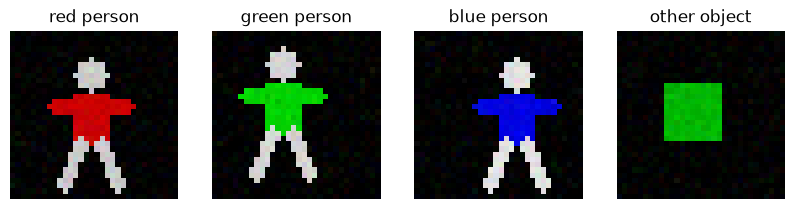

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report
from tempfile import TemporaryDirectory
from pathlib import Path

torch.manual_seed(21)
torch.set_num_threads(2)
labels = ["red person", "green person", "blue person", "other object"]
# Channel order is RGB throughout this synthetic example.
clothing_colours = [(1, 0, 0), (0, 1, 0), (0, 0, 1)]

def make_dataset(seed, per_class):
    """Create independent labelled cartoon images using a reproducible random seed."""
    rng = np.random.default_rng(seed)
    images, targets = [], []
    for label in range(len(labels)):
        for _ in range(per_class):
            image = np.zeros((32, 32, 3), dtype=np.uint8)
            x = int(rng.integers(13, 20))
            y = int(rng.integers(2, 6))
            brightness = int(rng.integers(170, 256))
            colour_index = label if label < 3 else int(rng.integers(3))
            colour = tuple(int(channel * brightness) for channel in clothing_colours[colour_index])
            if label < 3:
                # The shirt colour is the label; head and legs are neutral grey.
                grey = (brightness, brightness, brightness)
                cv2.circle(image, (x, y + 3), 3, grey, -1)
                cv2.rectangle(image, (x-3, y+7), (x+3, y+16), colour, -1)
                cv2.line(image, (x-7, y+9), (x+7, y+9), colour, 2)
                cv2.line(image, (x-2, y+16), (x-5, y+24), grey, 2)
                cv2.line(image, (x+2, y+16), (x+5, y+24), grey, 2)
            else:
                size = int(rng.integers(5, 10))
                centre_y = int(rng.integers(12, 20))
                if rng.integers(2):
                    cv2.circle(image, (x, centre_y), size, colour, -1)
                else:
                    cv2.rectangle(image, (x-size, centre_y-size),
                                  (x+size, centre_y+size), colour, -1)
            noise = rng.normal(0, 8, (32, 32, 3))
            images.append(np.clip(image.astype(float) + noise, 0, 255).astype(np.float32) / 255)
            targets.append(label)
    # PyTorch convolutions expect (samples, channels, height, width).
    return torch.tensor(np.array(images)).permute(0, 3, 1, 2), torch.tensor(targets)

X_train, y_train = make_dataset(seed=21, per_class=150)
X_test, y_test = make_dataset(seed=99, per_class=40)
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, index in zip(axes, [0, 150, 300, 450]):
    ax.imshow(X_train[index].permute(1, 2, 0).numpy())
    ax.set_title(labels[y_train[index].item()])
    ax.axis("off")
plt.show()

## Train the CNN

Two small convolution layers and pooling keep the model lightweight. The first layer accepts three RGB channels and the final layer produces one score per class. Cross-entropy uses integer labels. Other objects also come in the three colours, so colour alone is not enough. The test images were independently generated and are not used in training.

In [5]:
def create_model():
    """Create the small CNN architecture used for training and inference."""
    return nn.Sequential(
        nn.Conv2d(3, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(8, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(16 * 8 * 8, len(labels))
    )

model = create_model()
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))
loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
loss_fn = nn.CrossEntropyLoss()
model.train()
for epoch in range(6):
    total_loss = 0.0
    for batch_x, batch_y in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(batch_x), batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(batch_x)
    print(f"Epoch {epoch+1}: mean loss {total_loss / len(X_train):.4f}")

Trainable parameters: 5492
Epoch 1: mean loss 1.1226
Epoch 2: mean loss 0.1770
Epoch 3: mean loss 0.0041
Epoch 4: mean loss 0.0009
Epoch 5: mean loss 0.0005
Epoch 6: mean loss 0.0004


## Evaluate and use the trained model

Set evaluation mode and disable gradient calculation for inference. The report evaluates all four classes on held-out synthetic crops. Save only weights; the same architecture, label order and preprocessing are required when loading. Only load trusted files. A permanent path can replace the temporary directory when transferring weights.

              precision    recall  f1-score   support

  red person       1.00      1.00      1.00        40
green person       1.00      1.00      1.00        40
 blue person       1.00      1.00      1.00        40
other object       1.00      1.00      1.00        40

    accuracy                           1.00       160
   macro avg       1.00      1.00      1.00       160
weighted avg       1.00      1.00      1.00       160

True: red person; predicted: red person; target (red person): True
True: green person; predicted: green person; target (red person): False
True: blue person; predicted: blue person; target (red person): False
True: other object; predicted: other object; target (red person): False


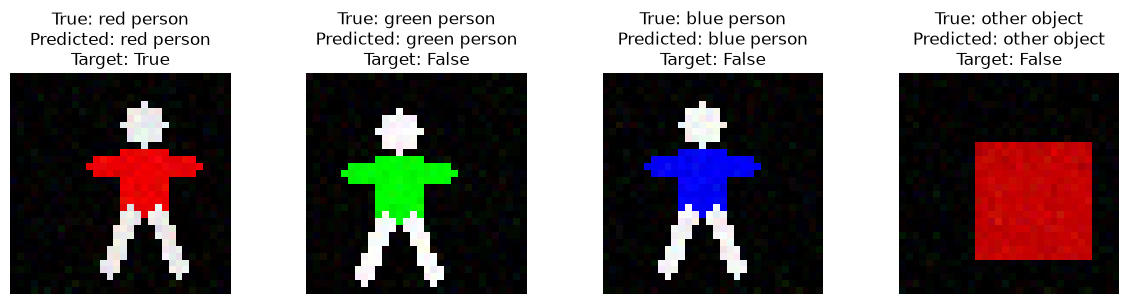

In [6]:
model.eval()
with torch.no_grad():
    predicted = model(X_test).argmax(dim=1)
print(classification_report(y_test.numpy(), predicted.numpy(), target_names=labels, zero_division=0))

with TemporaryDirectory() as folder:
    path = Path(folder) / "shape_weights.pt"
    torch.save(model.state_dict(), path)
    loaded_model = create_model()
    loaded_model.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
    loaded_model.eval()
    with torch.no_grad():
        probabilities = loaded_model(X_test).softmax(dim=1)

# Choose a target shirt colour and inspect one held-out crop from each class.
target_label = "red person"  # Try "green person" or "blue person".
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, index in zip(axes, [0, 40, 80, 120]):
    prediction = labels[int(probabilities[index].argmax())]
    is_target = prediction == target_label
    print(f"True: {labels[y_test[index].item()]}; predicted: {prediction}; "
          f"target ({target_label}): {is_target}")
    ax.imshow(X_test[index].permute(1, 2, 0).numpy())
    ax.set_title(f"True: {labels[y_test[index].item()]}\nPredicted: {prediction}\nTarget: {is_target}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Towards Task B

For an OpenCV BGR camera crop, convert it to RGB, resize to 32×32, divide pixel values by 255, and arrange the tensor as `(1, 3, 32, 32)` before inference, matching the training pipeline. The selected clothing-colour class is not a person's identity: people wearing similar colours remain ambiguous. A real system needs labelled crops of the actual target and decoys across scenes, poses and lighting; split by person/scene before training to avoid leakage. A separate detector must locate people before classification, and a tracker must preserve the correct identity when people look similar. Combine tracking with distance measurements and safe robot control. This toy test score says nothing about performance on real people; measure speed and accuracy on the Raspberry Pi and robot.